# REACTIV — Polarimetric UAVSAR time series

**Reproducible demonstration — Google Colab / local Jupyter**

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/elisecolin/REACTIV/blob/master/Python/Tuto_REACTIV_UAVSAR.ipynb)

This notebook adapts the REACTIV Polarimetric algorithm to the NaN-aware, vectorized `reactiv_fast.py` implementation.
It uses three co-registered, complex-valued UAVSAR temporal stacks: **HH**, **HV**, and **VV**, published as `.npy` assets in a [GitHub Release](https://github.com/elisecolin/REACTIV/releases) (not in a Git branch).

**Contents:** download and cache, quality control, single-channel intensity CVs, generalized multivariate CVs and their spectral bounds, Pauli-like intensity combinations, and the phase-sensitive two-component / four-observable construction.

**Scientific conventions**

- Each complex stack has shape `(Nt, Nx, Ny)` (time, row, column), and is spatially registered across dates and channels.
- The *multivariate* CVs are computed on real-valued **intensity** series, e.g. `|S_HH|²`; they must not be fed complex SAR values.
- A date is used in the multivariate estimation only if **all channels are finite** at that pixel. Pixels with fewer than two common valid dates are undefined (`NaN`).
- `Lmin` and `Lmax` denote bounds on the **generalized CV** (not the covariance eigenvalues themselves).
- Results depend on the image registration, temporal sampling, and any preprocessing of the source UAVSAR SLCs. This notebook does not reproduce that preprocessing.

**References:**

Colin & Nicolas, *Remote Sensing* 12 (2020), 2089, [doi:10.3390/rs12132089](https://doi.org/10.3390/rs12132089);

Colin & Ossikovski, *J. Indian Soc. Remote Sens.* 52 (2024), 2625–2636.

## 1. Configuration

Run the cells from top to bottom. **Default mode uses a spatial crop** (384 × 384 pixels, if available) to limit computation time and memory. Set `MAX_DEMO_SIZE = None` to process the entire scene (a higher-RAM Colab runtime may be needed). The data files are downloaded only once per Colab session. To retain them across sessions, set `DATA_DIR` to a Google Drive directory after mounting your Drive.

The downloader identifies assets by the polarization suffix (`_xx`, `_xy`, `_yy`) or by explicit (`HH`, `HV`, `VV`) tokens. If your release uses other names, edit `ASSET_NAMES` with their exact filenames.

In [67]:
from pathlib import Path
import os
import re
import sys
import importlib.util
import warnings

import numpy as np
import matplotlib.pyplot as plt
import requests

REPOSITORY = "elisecolin/REACTIV"
CODE_BRANCH = "master"
RELEASE_TAG = "UAVSAR"  # If different, the downloader will show available releases.

# Optional explicit names, e.g. {"HH": "SanFrancisco_xx.npy", ...}.
ASSET_NAMES = {"HH": None, "HV": None, "VV": None}

DATA_DIR = Path(os.environ.get("UAVSAR_LOCAL_DIR", "/content/REACTIV_data/UAVSAR"))
CODE_DIR = Path("/content/REACTIV_code")
MAX_DEMO_SIZE = None # None -> entire scene
ROI = None           # optional (row_start, row_end, col_start, col_end)
CHUNK_PIXELS = 8192  # memory/performance balance for matrix eigendecompositions
FORCE_DOWNLOAD = False

DATA_DIR.mkdir(parents=True, exist_ok=True)
CODE_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 105, "axes.grid": False})
print("Data cache:", DATA_DIR)

Data cache: /content/REACTIV_data/UAVSAR


## 2. Import the algorithm from the repository's `master` branch

A fresh copy of `Python/reactiv_fast.py` is retrieved whenever the notebook runs, except when a local override is provided for offline testing. Thus the notebook uses the version published on GitHub, without `pip install`, or cloning the repository.

In [68]:
def get_fast_module():
    local = os.environ.get("REACTIV_FAST_LOCAL_PATH")
    destination = CODE_DIR / "reactiv_fast.py"
    if local:
        destination.write_bytes(Path(local).read_bytes())
        print("Using local module override:", local)
    else:
        url = (f"https://raw.githubusercontent.com/{REPOSITORY}/"
               f"{CODE_BRANCH}/Python/reactiv_fast.py")
        response = requests.get(url, timeout=60)
        response.raise_for_status()
        content = response.content
        if b"def " not in content and b"import " not in content:
            raise RuntimeError("Downloaded source does not look like Python code.")
        destination.write_bytes(content)
        print("Module source:", url)
    spec = importlib.util.spec_from_file_location("reactiv_fast_notebook", destination)
    module = importlib.util.module_from_spec(spec)
    sys.modules[spec.name] = module
    spec.loader.exec_module(module)
    required = ["CV_Generalized_Limits", "CV_fromListofImages", "CV_Generalized_equally",
                "CV_Generalized_Non_equally", "CV_Generalized_Non_equally_Zero",
                "polar_valid_counts", "Stack2SingleCV", "covariance_matrix"]
    missing = [name for name in required if not hasattr(module, name)]
    if missing:
        raise RuntimeError(f"reactiv_fast.py from master is missing: {missing}. "
                           "Verify that the updated module was committed to master.")
    return module

rf = get_fast_module()
print("reactiv_fast loaded.\nAvailable generalized-CV routines:",
      rf.CV_Generalized_Limits.__name__, rf.CV_Generalized_equally.__name__)

Module source: https://raw.githubusercontent.com/elisecolin/REACTIV/master/Python/reactiv_fast.py
reactiv_fast loaded.
Available generalized-CV routines: CV_Generalized_Limits CV_Generalized_equally


## 3. Locate and download the UAVSAR Release assets

The GitHub **Release** stores binary files associated with a Git tag; it is not another branch. The GitHub Releases API supplies the actual asset filenames and download URLs. Downloads use streaming, a temporary `.part` file, and atomic rename. Existing valid `.npy` files are reused.

If the tag is not found, the cell lists published releases to help correct `RELEASE_TAG`. If the automatic filename matching is ambiguous, fill in `ASSET_NAMES` in the configuration cell.

In [69]:
def list_release_assets(tag):
    api = f"https://api.github.com/repos/{REPOSITORY}/releases/tags/{tag}"
    r = requests.get(api, timeout=45, headers={"Accept": "application/vnd.github+json"})
    if r.status_code == 404:
        other = requests.get(f"https://api.github.com/repos/{REPOSITORY}/releases",
                             timeout=45, headers={"Accept": "application/vnd.github+json"})
        other.raise_for_status()
        tags = [x.get("tag_name") for x in other.json()]
        raise RuntimeError(f"Release tag {tag!r} not found. Published tags: {tags}. "
                           "Update RELEASE_TAG above.")
    r.raise_for_status()
    result = r.json()
    assets = [a for a in result.get("assets", []) if a["name"].lower().endswith(".npy")]
    if not assets:
        raise RuntimeError("Release exists but has no .npy asset. Check that the three "
                           "files were uploaded as release assets (not just source archives).")
    print(f"Release: {result['name'] or result['tag_name']} (tag {result['tag_name']})")
    for a in assets:
        print(f"  {a['name']:50s} {a['size']/1024**2:8.1f} MiB")
    return assets


def identify_asset(name):
    stem = Path(name).stem.lower()
    parts = set(filter(None, re.split(r"[^a-z0-9]+", stem)))
    labels = {
        "HH": {"hh", "xx", "exx", "shh"},
        "HV": {"hv", "vh", "xy", "exy", "shv", "sxy"},
        "VV": {"vv", "yy", "eyy", "svv"},
    }
    found = [pol for pol, variants in labels.items() if parts & variants]
    return found[0] if len(found) == 1 else None


def select_assets(assets):
    chosen = {}
    for pol in ("HH", "HV", "VV"):
        explicit = ASSET_NAMES.get(pol)
        matches = ([a for a in assets if a["name"] == explicit] if explicit else
                   [a for a in assets if identify_asset(a["name"]) == pol])
        if len(matches) != 1:
            raise RuntimeError(f"Cannot uniquely identify {pol} from release assets. "
                               f"Matches: {[a['name'] for a in matches]}. "
                               "Set ASSET_NAMES with the exact filenames above.")
        chosen[pol] = matches[0]
    if len({a['id'] for a in chosen.values()}) != 3:
        raise RuntimeError("The three polarizations must correspond to three distinct files.")
    return chosen


def valid_npy(path):
    try:
        with open(path, "rb") as f:
            return f.read(6) == b"\x93NUMPY"
    except OSError:
        return False


def download_asset(asset, dest, force=False):
    expected = int(asset.get("size") or 0)
    if (not force and dest.is_file() and valid_npy(dest)
            and (not expected or dest.stat().st_size == expected)):
        print("Using cache:", dest.name)
        return dest
    tmp = dest.with_suffix(dest.suffix + ".part")
    try:
        with requests.get(asset["browser_download_url"], stream=True,
                          timeout=(30, 240), allow_redirects=True) as r:
            r.raise_for_status()
            with open(tmp, "wb") as f:
                size = 0
                for block in r.iter_content(chunk_size=2**20):
                    if block:
                        f.write(block)
                        size += len(block)
        if expected and size != expected:
            raise IOError(f"Incomplete download of {dest.name}: {size} != {expected} bytes")
        if not valid_npy(tmp):
            raise IOError(f"{dest.name} is not a valid NumPy .npy file "
                          "(possible HTML response or Git LFS pointer).")
        tmp.replace(dest)
        print(f"Downloaded {dest.name} ({size / 1024**2:.1f} MiB)")
        return dest
    finally:
        tmp.unlink(missing_ok=True)


# Offline mode for local tests; Colab normally uses the GitHub Release API.
local_mode = bool(os.environ.get("UAVSAR_LOCAL_DIR"))
if local_mode:
    files = list(DATA_DIR.glob("*.npy"))
    assets = [{"id": i, "name": f.name, "size": f.stat().st_size,
               "browser_download_url": ""} for i, f in enumerate(files)]
    print("Local dataset override:", DATA_DIR)
else:
    assets = list_release_assets(RELEASE_TAG)
selected = select_assets(assets)
paths = ({pol: DATA_DIR / item["name"] for pol, item in selected.items()}
         if local_mode else
         {pol: download_asset(item, DATA_DIR/item["name"], FORCE_DOWNLOAD)
          for pol, item in selected.items()})
for pol, path in paths.items():
    if not path.exists() or not valid_npy(path):
        raise RuntimeError(f"Missing or invalid {pol} stack: {path}")
print("Selected files:", {p: f.name for p, f in paths.items()})

Release: REACTIV — UAVSAR demonstration dataset. (tag UAVSAR)
  SanFrancisco_xx.npy                                    73.2 MiB
  SanFrancisco_xy.npy                                    73.2 MiB
  SanFrancisco_yy.npy                                    73.2 MiB
Using cache: SanFrancisco_xx.npy
Using cache: SanFrancisco_xy.npy
Using cache: SanFrancisco_yy.npy
Selected files: {'HH': 'SanFrancisco_xx.npy', 'HV': 'SanFrancisco_xy.npy', 'VV': 'SanFrancisco_yy.npy'}


## 4. Inspect stacks and select the study region

Files are opened via `np.load(..., mmap_mode="r")`: source data remain on disk until a crop is used. No automatic change in axis order, phase, or unit is performed. The three stacks **must** be complex and have identical `(Nt,Nx,Ny)` shapes. A readable report of invalid samples is produced, including pixels where fewer than two dates are simultaneously valid.

In [70]:
stacks = {pol: np.load(path, mmap_mode="r", allow_pickle=False)
          for pol, path in paths.items()}
shape = stacks["HH"].shape
for pol, arr in stacks.items():
    if arr.ndim != 3 or arr.shape != shape:
        raise ValueError(f"{pol}: expected identical (Nt,Nx,Ny) shapes; got {arr.shape}, expected {shape}.")
    if not np.issubdtype(arr.dtype, np.complexfloating):
        raise TypeError(f"{pol}: expected COMPLEX SAR amplitudes, found dtype {arr.dtype}")
if shape[0] < 2:
    raise ValueError("At least two acquisition dates are required.")
print("Full stack dimensions (Nt, rows, columns):", shape)
print("Array dtypes:", {pol: str(arr.dtype) for pol, arr in stacks.items()})

Nt, Nx, Ny = shape
if ROI is not None:
    if len(ROI) != 4:
        raise ValueError("ROI must be (row0, row1, col0, col1).")
    r0, r1, c0, c1 = map(int, ROI)
else:
    width = min(Ny, MAX_DEMO_SIZE) if MAX_DEMO_SIZE is not None else Ny
    height = min(Nx, MAX_DEMO_SIZE) if MAX_DEMO_SIZE is not None else Nx
    r0, r1 = (Nx-height)//2, (Nx-height)//2 + height
    c0, c1 = (Ny-width)//2, (Ny-width)//2 + width
if not (0 <= r0 < r1 <= Nx and 0 <= c0 < c1 <= Ny):
    raise ValueError(f"ROI out of bounds for {(Nx,Ny)}: {(r0,r1,c0,c1)}")
print("Chosen region (rows, columns):", (r0, r1, c0, c1))

# Crop before materializing arrays. Complex data are retained (phase not discarded).
S = {pol: np.asarray(arr[:, r0:r1, c0:c1]) for pol, arr in stacks.items()}
HH, HV, VV = S["HH"], S["HV"], S["VV"]
Nt, H, W = HH.shape
joint_counts = rf.polar_valid_counts([HH, HV, VV], chunk_pixels=CHUNK_PIXELS)
valid_map = joint_counts >= 2
print("ROI shape:", HH.shape)
print("Joint valid-date count min / median / max:",
      int(joint_counts.min()), float(np.median(joint_counts)), int(joint_counts.max()))
print(f"Undefined pixels (<2 jointly valid dates): {(~valid_map).sum():,} / {H*W:,}")
for pol, arr in S.items():
    bad = np.count_nonzero(~np.isfinite(arr))
    print(f"{pol}: invalid complex samples = {bad:,} / {arr.size:,}")

Full stack dimensions (Nt, rows, columns): (12, 400, 1000)
Array dtypes: {'HH': 'complex128', 'HV': 'complex128', 'VV': 'complex128'}
Chosen region (rows, columns): (0, 400, 0, 1000)
ROI shape: (12, 400, 1000)
Joint valid-date count min / median / max: 12 12.0 12
Undefined pixels (<2 jointly valid dates): 0 / 400,000
HH: invalid complex samples = 0 / 4,800,000
HV: invalid complex samples = 0 / 4,800,000
VV: invalid complex samples = 0 / 4,800,000


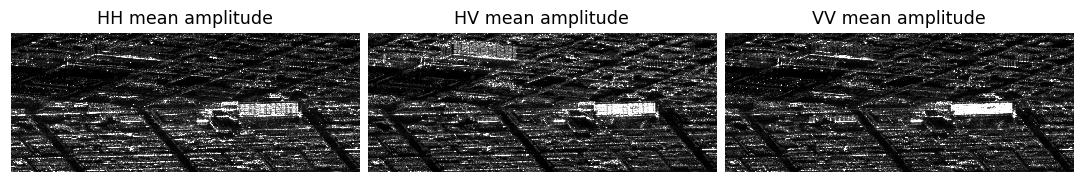

In [71]:
# First look: average backscattered intensity and map of valid acquisitions.
def percentile_stretch(im, lo=2, hi=98):
    im = np.asarray(im, dtype=float)
    ok = np.isfinite(im)
    if not ok.any():
        return np.full(im.shape, np.nan)
    a, b = np.percentile(im[ok], [lo, hi])
    if b <= a:
        return np.where(ok, 0.0, np.nan)
    return np.where(ok, np.clip((im-a)/(b-a), 0, 1), np.nan)

def show_maps(images, titles, cmap="gray", cols=3, size=4.0):
    n = len(images)
    rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(cols*size, rows*size*0.83),
                             squeeze=False, constrained_layout=True)
    cm = plt.colormaps[cmap].copy()
    cm.set_bad("black")
    for ax, im, title in zip(axes.flat, images, titles):
        ax.imshow(np.ma.masked_invalid(im), cmap=cm, interpolation="nearest")
        ax.set(title=title)
        ax.axis("off")
    for ax in list(axes.flat)[n:]:
        ax.axis("off")
    return fig

mean_amplitudes = [np.nanmean(np.abs(np.where(np.isfinite(S[p]), S[p], np.nan)), axis=0)
                   for p in ("HH", "HV", "VV")]
show_maps([percentile_stretch(v) for v in mean_amplitudes],
          ["HH mean amplitude", "HV mean amplitude", "VV mean amplitude"], cols=3, size=3.4)
plt.show()

## 5. Individual-channel CVs and generalized CVs in the HH/HV/VV intensity basis

We first convert complex amplitudes to real **intensities**. For consistency between the scalar and multivariate estimates, the same *jointly finite* temporal mask is used for HH, HV, and VV. Missing acquisitions remain `NaN`, not zeros.

The scalar CVs here are $\sigma(I_i)/\mathbb{E}[I_i]$ for **intensity**; they are not the amplitude-domain, Rayleigh-normalized scalar REACTIV maps. The multivariate CVs use the covariance matrix $C$ of the three intensity series and the temporal mean vector $\mu$.

The spectral bounds are

$$\gamma_{\min}=\frac{\sqrt{\lambda_{\min}(C)}}{\|\mu\|},\qquad
  \gamma_{\max}=\frac{\sqrt{\lambda_{\max}(C)}}{\|\mu\|}.$$

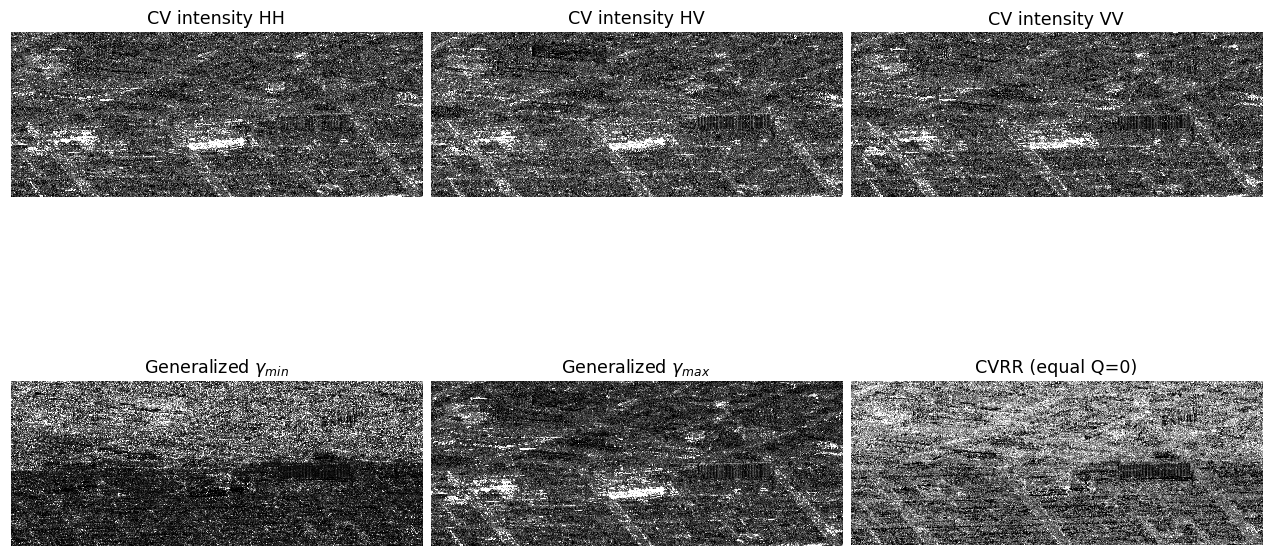

In [72]:
# The joint mask ensures the same set of dates for every multivariate channel.
joint_finite = np.isfinite(HH) & np.isfinite(HV) & np.isfinite(VV)
I_HH = np.where(joint_finite, np.abs(HH)**2, np.nan)
I_HV = np.where(joint_finite, np.abs(HV)**2, np.nan)
I_VV = np.where(joint_finite, np.abs(VV)**2, np.nan)
P3 = [I_HH, I_HV, I_VV]

# Scalar intensity CV, joint omission, >=2 dates.
scalar = {}
for name, intensity in zip(("HH", "HV", "VV"), P3):
    cv = rf.Stack2SingleCV(intensity, timeaxis=0, nan_policy="omit")
    cv[~valid_map] = np.nan
    scalar[name] = cv

Lmin3, Lmax3 = rf.CV_Generalized_Limits(P3, chunk_pixels=CHUNK_PIXELS)
CVRR, CVgv, CVVN, CVAZ = rf.CV_fromListofImages(P3, chunk_pixels=CHUNK_PIXELS)
CVeq1 = rf.CV_Generalized_equally(P3, Q=1, chunk_pixels=CHUNK_PIXELS)
CVne0 = rf.CV_Generalized_Non_equally_Zero(P3, chunk_pixels=CHUNK_PIXELS)

show_maps([percentile_stretch(scalar[p]) for p in ("HH", "HV", "VV")]
          + [percentile_stretch(Lmin3), percentile_stretch(Lmax3),
             percentile_stretch(CVRR)],
          ["CV intensity HH", "CV intensity HV", "CV intensity VV",
           r"Generalized $\gamma_{min}$", r"Generalized $\gamma_{max}$",
           "CVRR (equal Q=0)"], cols=3)
plt.show()

### Other historical multivariate coefficients and normalization checks

The earlier notebook equated `CVgv` with `CV_Generalized_equally(P3, 1)`. In fact the current module preserves the earlier **trace** convention for `CVgv`, whereas the generalized equal-weight definition averages eigenvalues: for three channels, `CVgv = sqrt(3) × CVeq(Q=1)`. The notebook checks this explicitly instead of silently changing the historical definition.

Similarly `CVAZ = CVne(Q=1)`, `CVVN = CVne(Q=-1)`, and `CVRR = CVeq(Q=0)` (where defined).

Check CVRR vs equal Q=0:         0.0
Check CVgv vs sqrt(3)*equal Q=1: 1.3322676295501878e-15
Check CVAZ vs weighted Q=1:      0.0
Check CVVN vs weighted Q=-1:     0.0


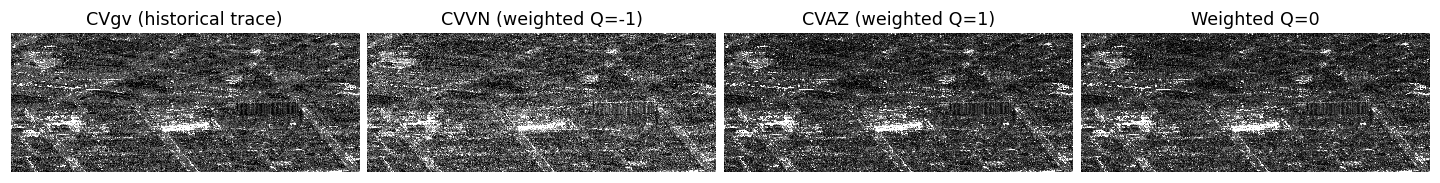

In [73]:
CVeq0 = rf.CV_Generalized_equally(P3, Q=0, chunk_pixels=CHUNK_PIXELS)
CVne1 = rf.CV_Generalized_Non_equally(P3, Q=1, chunk_pixels=CHUNK_PIXELS)
CVne_minus1 = rf.CV_Generalized_Non_equally(P3, Q=-1, chunk_pixels=CHUNK_PIXELS)

def max_difference(a, b):
    both = np.isfinite(a) & np.isfinite(b)
    return float(np.max(np.abs(a[both] - b[both]))) if both.any() else np.nan

print("Check CVRR vs equal Q=0:        ", max_difference(CVRR, CVeq0))
print("Check CVgv vs sqrt(3)*equal Q=1:", max_difference(CVgv, np.sqrt(3)*CVeq1))
print("Check CVAZ vs weighted Q=1:     ", max_difference(CVAZ, CVne1))
print("Check CVVN vs weighted Q=-1:    ", max_difference(CVVN, CVne_minus1))

show_maps([percentile_stretch(x) for x in (CVgv, CVVN, CVAZ, CVne0)],
          ["CVgv (historical trace)", "CVVN (weighted Q=-1)",
           "CVAZ (weighted Q=1)", "Weighted Q=0"], cols=4, size=3.4)
plt.show()

## 6. Alternative polarimetric representations

### 6.1. Pauli-like intensity combinations

We evaluate the three real temporal observables

$$|S_{HH}-S_{VV}|^2,\qquad |2S_{HV}|^2,\qquad |S_{HH}+S_{VV}|^2.$$



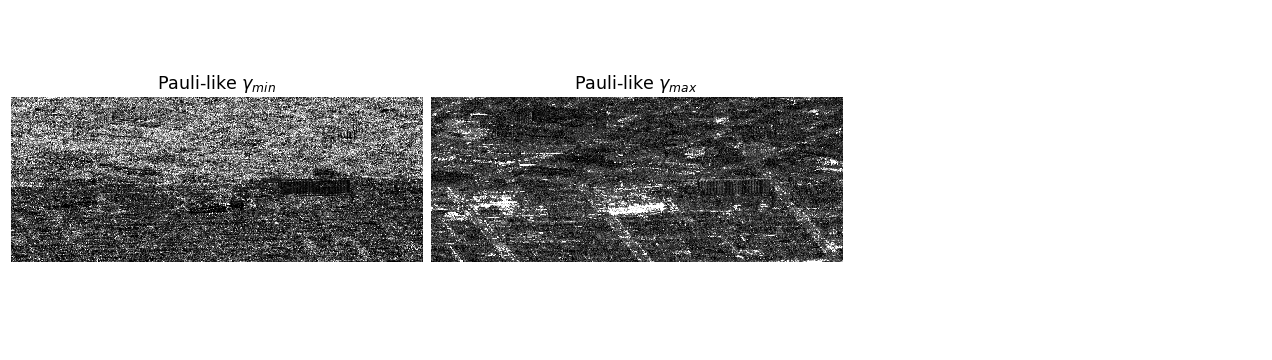

In [74]:
P_pauli = [np.where(joint_finite, np.abs(HH - VV)**2, np.nan),
           np.where(joint_finite, np.abs(2*HV)**2, np.nan),
           np.where(joint_finite, np.abs(HH + VV)**2, np.nan)]

Lmin_pauli, Lmax_pauli = rf.CV_Generalized_Limits(P_pauli, chunk_pixels=CHUNK_PIXELS)

show_maps([percentile_stretch(Lmin_pauli), percentile_stretch(Lmax_pauli)],
          [r"Pauli-like $\gamma_{min}$", r"Pauli-like $\gamma_{max}$"],
          cols=3)
plt.show()

In [75]:
# ============================================================
# Quick Pauli RGB display
# ============================================================

def _robust_scale(x, q=99):
    x = np.asarray(x, dtype=float)
    valid = np.isfinite(x)
    if not np.any(valid):
        return np.zeros_like(x)
    vmax = np.percentile(x[valid], q)
    if vmax <= 0:
        vmax = np.max(x[valid])
    if vmax <= 0:
        return np.zeros_like(x)
    return np.clip(x / vmax, 0, 1)

def pauli_rgb(HH, HV, VV, q=99):
    R = np.abs(HH - VV)**2
    G = np.abs(2 * HV)**2
    B = np.abs(HH + VV)**2

    rgb = np.stack([
        _robust_scale(R, q=q),
        _robust_scale(G, q=q),
        _robust_scale(B, q=q)
    ], axis=-1)

    rgb[~np.isfinite(rgb)] = 0
    return rgb

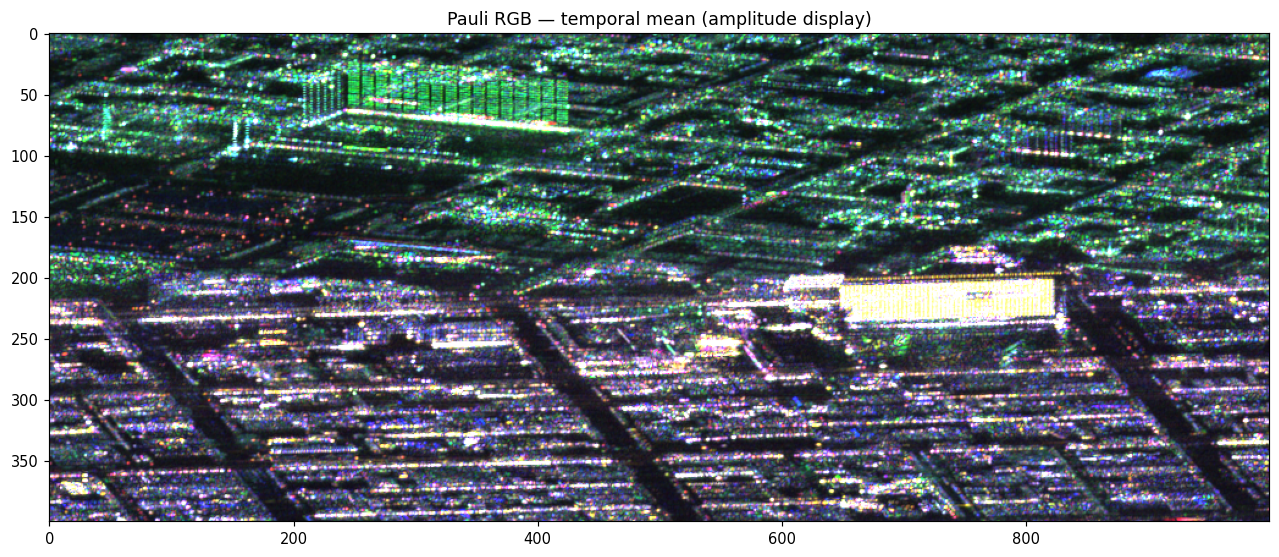

In [76]:
# ============================================================
# Pauli RGB — temporal mean, amplitude display
# ============================================================

HH, HV, VV = S["HH"], S["HV"], S["VV"]

valid = (
    np.isfinite(HH) &
    np.isfinite(HV) &
    np.isfinite(VV)
)

def temporal_mean_intensity(z):
    return np.nanmean(
        np.where(valid, np.abs(z)**2, np.nan),
        axis=0
    )

# Temporally averaged Pauli intensities
R = temporal_mean_intensity(HH - VV)
G = temporal_mean_intensity(2 * HV)
B = temporal_mean_intensity(HH + VV)

# Display in amplitude rather than intensity
R, G, B = np.sqrt(R), np.sqrt(G), np.sqrt(B)

def normalize(x, q=95, gamma=1):
    finite = x[np.isfinite(x)]
    threshold = np.percentile(finite, q)
    y = np.clip(x / max(threshold, 1e-12), 0, 1)
    return np.nan_to_num(y**gamma)

rgb = np.stack([
    normalize(R),
    normalize(G),
    normalize(B)
], axis=-1)

plt.figure(figsize=(15, 9))
plt.imshow(rgb)
plt.title("Pauli RGB — temporal mean (amplitude display)")
#plt.axis("off")
plt.show()

### 6.2. Two complex components and Stokes-derived real observables

The otebook also constructs four nonnegative intensity observables from the Stokes parameters of the *two-component* complex vector $(S_{HH}, S_{HV})$ for horizontal transmission. It does **not** use all three independent scattering-matrix entries in a full polarimetric coherency-matrix construction.

For $E_x=S_{HH}$ and $E_y=S_{HV}$, the Stokes components are

$$S_0=|E_x|^2+|E_y|^2,\quad S_1=|E_x|^2-|E_y|^2,\quad
S_2=2\Re(E_xE_y^*),\quad S_3=2\Im(E_xE_y^*).$$

The sign of $S_3$ depends on convention. The four real observables correspond to projections along tetrahedral Stokes directions.

Stokes-derived observables: 4 real intensity series


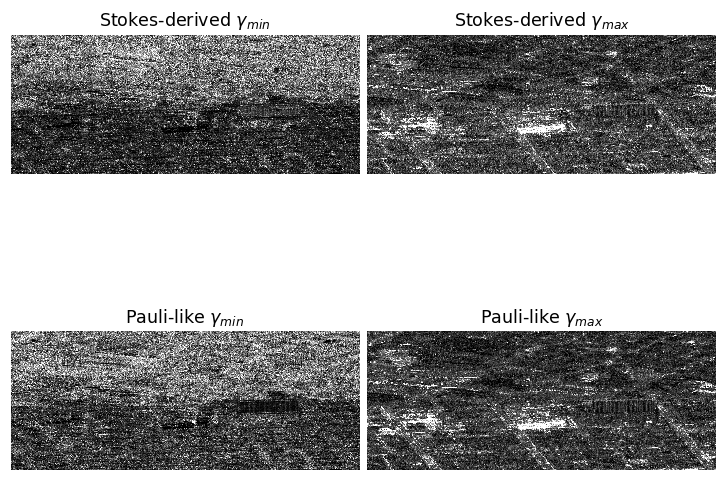

In [77]:
def jones_to_stokes(ex, ey):
    s0 = np.abs(ex)**2 + np.abs(ey)**2
    s1 = np.abs(ex)**2 - np.abs(ey)**2
    cross = ex * np.conj(ey)
    s2 = 2*np.real(cross)
    s3 = 2*np.imag(cross)
    return s0, s1, s2, s3

def stokes_to_four_intensities(s0, s1, s2, s3):
    a = 1 / np.sqrt(3)
    return [s0+a*( s1+s2+s3),
            s0+a*( s1-s2-s3),
            s0+a*(-s1-s2+s3),
            s0+a*(-s1+s2-s3)]

S0, S1, S2, S3 = jones_to_stokes(HH, HV)
P4 = [np.where(joint_finite, im, np.nan) for im in
      stokes_to_four_intensities(S0, S1, S2, S3)]
Lmin4, Lmax4 = rf.CV_Generalized_Limits(P4, chunk_pixels=CHUNK_PIXELS)

print("Stokes-derived observables: 4 real intensity series")
show_maps([percentile_stretch(Lmin4), percentile_stretch(Lmax4),
           percentile_stretch(Lmin_pauli), percentile_stretch(Lmax_pauli)],
          [r"Stokes-derived $\gamma_{min}$", r"Stokes-derived $\gamma_{max}$",
           r"Pauli-like $\gamma_{min}$", r"Pauli-like $\gamma_{max}$"],
          cols=2, size=3.4)
plt.show()

## 7. Temporal profile and covariance matrix for one pixel

Choose a pixel in *ROI coordinates* `(row, column)` (not full-scene coordinates). This produces the profile-level analysis, while respecting the common valid-date mask and population covariance normalization (`ddof=0`).

Pixel (270, 500) (full image row 270, column 500), valid dates: 12 / 12
Population covariance C:
 [[239.15141529  11.13379384  24.64655165]
 [ 11.13379384   0.55106889   1.1655019 ]
 [ 24.64655165   1.1655019    2.64037884]]
Eigenvalues of C: [2.81921721e-02 1.03589923e-01 2.42211081e+02]


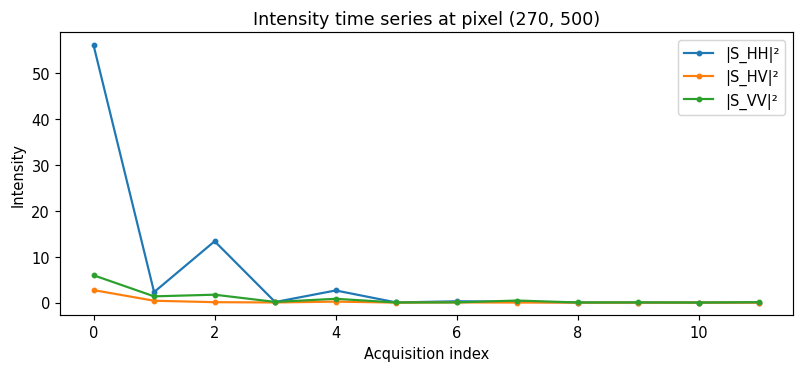

In [78]:
PIXEL = (270, 500)  # Change this pair if you wish.
x, y = PIXEL
if not (0 <= x < H and 0 <= y < W):
    raise ValueError(f"PIXEL={PIXEL} is outside the ROI {(H,W)}")

X = np.stack([v[:, x, y] for v in P3], axis=0)
ok_t = np.all(np.isfinite(X), axis=0)
print(f"Pixel {PIXEL} (full image row {r0+x}, column {c0+y}), "
      f"valid dates: {ok_t.sum()} / {Nt}")
if ok_t.sum() >= 2:
    covariance = rf.covariance_matrix(X, nan_policy="omit")
    print("Population covariance C:\n", covariance)
    print("Eigenvalues of C:", np.linalg.eigvalsh(covariance))
else:
    print("Covariance undefined: fewer than two common valid dates.")

fig, ax = plt.subplots(figsize=(9, 3.5))
for name, line in zip(("HH", "HV", "VV"), X):
    ax.plot(np.arange(Nt), line, ".-", label=f"|S_{name}|²")
for t in np.flatnonzero(~ok_t):
    ax.axvspan(t-0.25, t+0.25, color="grey", alpha=0.15)
ax.set(xlabel="Acquisition index", ylabel="Intensity",
       title=f"Intensity time series at pixel {PIXEL}")
ax.legend()
plt.show()

## 8. Generalized CV as a function of $Q$ (single-pixel diagnostic)

The two families of generalized CV are compared with their spectral limits. This operates on a `1 × 1` spatial crop and is therefore inexpensive even with many values of $Q$. Values for $Q=0$ are computed using the continuous logarithmic limit in `reactiv_fast.py`.

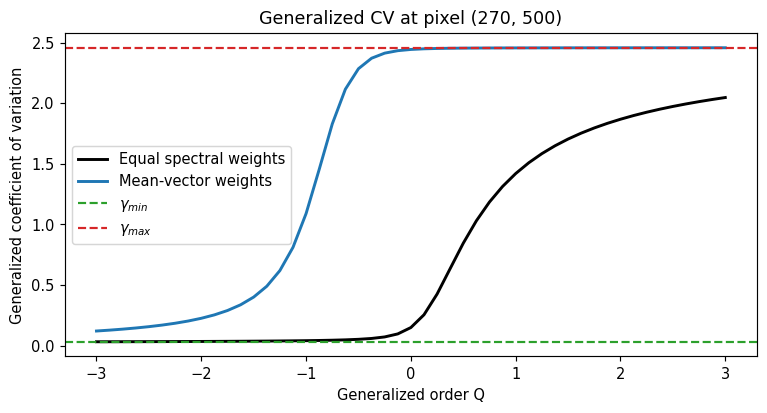

In [79]:
if ok_t.sum() >= 2:
    pixel_stack = [v[:, x:x+1, y:y+1] for v in P3]
    qs = np.linspace(-3.0, 3.0, 49)
    eq = [rf.CV_Generalized_equally(pixel_stack, float(q),
                                   chunk_pixels=1)[0, 0] for q in qs]
    we = [rf.CV_Generalized_Non_equally(pixel_stack, float(q),
                                       chunk_pixels=1)[0, 0] for q in qs]
    small, large = rf.CV_Generalized_Limits(pixel_stack, chunk_pixels=1)
    fig, ax = plt.subplots(figsize=(8.5, 4))
    ax.plot(qs, eq, "k-", lw=2, label="Equal spectral weights")
    ax.plot(qs, we, color="tab:blue", lw=2, label="Mean-vector weights")
    ax.axhline(small[0,0], color="tab:green", linestyle="--", label=r"$\gamma_{min}$")
    ax.axhline(large[0,0], color="tab:red", linestyle="--", label=r"$\gamma_{max}$")
    ax.set(xlabel="Generalized order Q", ylabel="Generalized coefficient of variation",
           title=f"Generalized CV at pixel {PIXEL}")
    ax.legend()
    plt.show()
else:
    print("Q-profile skipped: insufficient valid dates at selected pixel.")

## 9. Comparing REACTIV representations using different coefficients of variation

We now explore alternative ways of constructing a REACTIV RGB composite from the three polarimetric channels (HH, HV, VV).

Three approaches are compared:

1. **Classical REACTIV fusion:** the maximum of the normalized amplitude-based CVs across the three polarizations.
2. **Maximum intensity CV:** the maximum of the three scalar CVs computed from the intensity time series \(|S_{pq}|^2\).
3. **Generalized CV (\(\gamma_{\max}\)):** a multivariate coefficient derived from the largest eigenvalue of the temporal covariance matrix of the three intensity channels, accounting for their joint fluctuations.

To isolate the influence of the CV definition, all three representations share the same hue (date of maximum selected by the classical fusion) and value (amplitude-based brightness). Only the saturation is modified.

The intensity-based CVs are scaled using a common percentile, whereas classical REACTIV retains its theoretical statistical normalization. Consequently, this comparison is primarily qualitative rather than a strictly calibrated comparison of change-detection performance.

**At first glance, the three RGB composites appear remarkably similar.** This suggests that, for the present dataset and visualization settings, the choice of CV has a limited visible influence on the final RGB representation. However, visual similarity does not necessarily imply statistical equivalence or identical change-detection sensitivity.

A quantitative comparison of the CV maps and their differences would be needed to assess whether the multivariate approach provides additional information beyond the maximum of the individual intensity CVs.

In [80]:
summary = {
    "dates": Nt,
    "ROI_shape": (H, W),
    "pixels_with_2+_valid_dates": int(valid_map.sum()),
    "fraction_undefined": float((~valid_map).mean()),
    "CVHH_finite_fraction": float(np.isfinite(scalar["HH"]).mean()),
    "generalized_CV_max_finite_fraction": float(np.isfinite(Lmax3).mean()),
    "source_release_tag": RELEASE_TAG,
}
for key, value in summary.items():
    print(f"{key}: {value}")
print("UAVSAR polarimetric demonstration completed.")

dates: 12
ROI_shape: (400, 1000)
pixels_with_2+_valid_dates: 400000
fraction_undefined: 0.0
CVHH_finite_fraction: 1.0
generalized_CV_max_finite_fraction: 1.0
source_release_tag: UAVSAR
UAVSAR polarimetric demonstration completed.


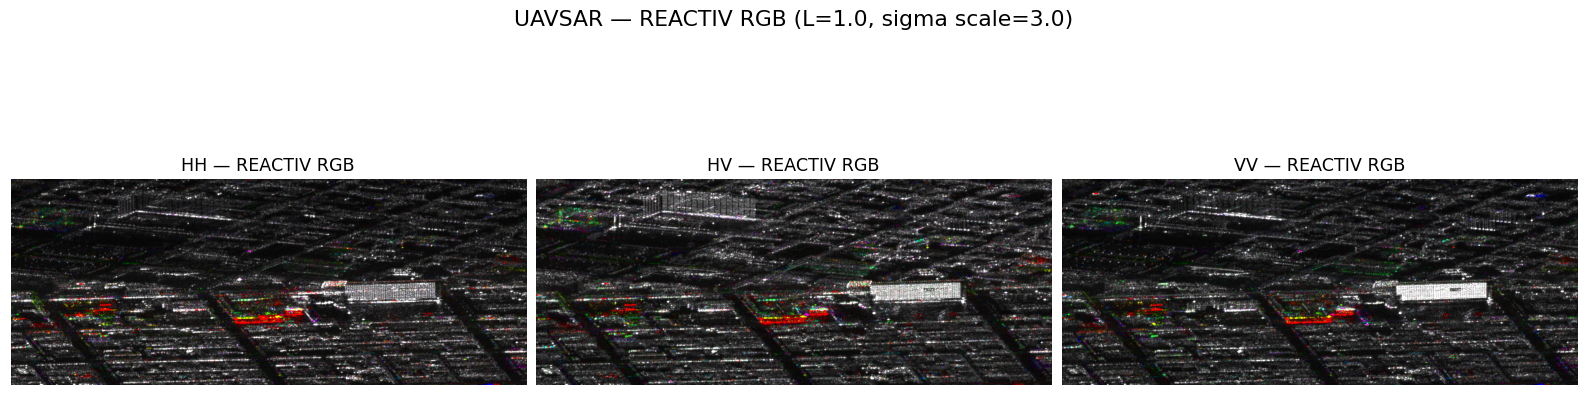

In [81]:
# ============================================================
# REACTIV RGB — HH, HV, VV (individual amplitude scaling)
# ============================================================

POL = ("HH", "HV", "VV")

L_REACTIV = 1.0
SIGMA_SCALE = 3.0  # Try 1, 3 or 10

reactiv_maps = {}

fig, axes = plt.subplots(
    1, 3, figsize=(15, 5), constrained_layout=True
)

for j, pol in enumerate(POL):

    # Complex SAR -> amplitude
    amplitude = np.where(
        joint_finite, np.abs(S[pol]), np.nan
    )

    CV, K, Amax, Nvalid = rf.Stack2reactiv(
        amplitude,
        timeaxis=0,
        L=L_REACTIV,
        sigma_scale=SIGMA_SCALE,
        nan_policy="omit",
        return_counts=True
    )

    reactiv_maps[pol] = (CV, K, Amax)

    # Individual scaling for each polarization
    finite_a = Amax[np.isfinite(Amax)]
    local_thresh = max(
        float(np.percentile(finite_a, 99)), 1e-12
    )

    rgb = rf.reactiv_image(
        CV, K, Amax, thresh=local_thresh
    )

    axes[j].imshow(rgb)
    axes[j].set_title(f"{pol} — REACTIV RGB")
    axes[j].axis("off")

plt.suptitle(
    f"UAVSAR — REACTIV RGB "
    f"(L={L_REACTIV}, sigma scale={SIGMA_SCALE})",
    fontsize=15
)
plt.show()

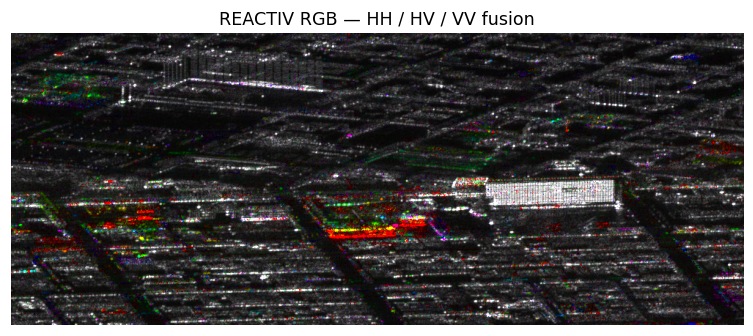

In [82]:
# ============================================================
# REACTIV RGB — Fusion of HH, HV and VV
# ============================================================

CVf, Kf, Af = reactiv_maps["HH"]

for pol in ("HV", "VV"):
    CVf, Kf, Af = rf.fusion2polar4reactiv(
        CVf, Kf, Af,
        *reactiv_maps[pol]
    )

# Display scaling of the fused image
fused_valid = Af[np.isfinite(Af)]
fused_thresh = max(
    float(np.percentile(fused_valid, 99)), 1e-12
)

RGB_fused = rf.reactiv_image(
    CVf, Kf, Af, thresh=fused_thresh
)

plt.figure(figsize=(9, 8))
plt.imshow(RGB_fused)
plt.title("REACTIV RGB — HH / HV / VV fusion")
plt.axis("off")
plt.show()

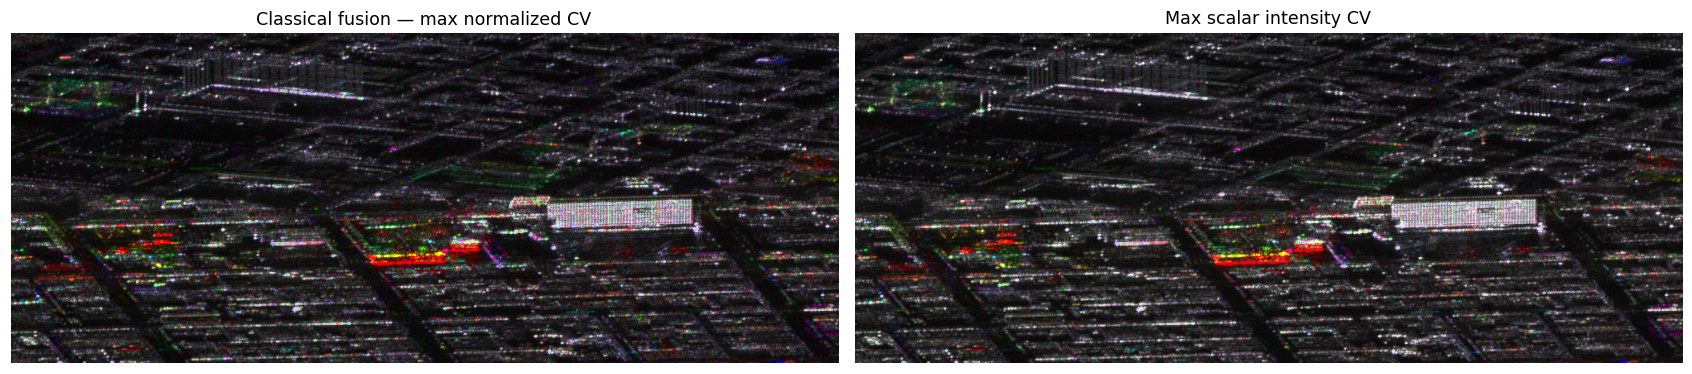

Maximum gamma_max - max(CV intensity): -0.0001372548287852382


In [85]:
# ============================================================
# REACTIV RGB — Classical fusion vs intensity-domain CVs
# ============================================================

# 1. Maximum of scalar intensity CVs
CVmax_I = np.maximum.reduce([
    scalar[p] for p in ("HH", "HV", "VV")
])

# 2. Generalized CV based on the largest covariance eigenvalue
CVgamma = Lmax3

# Common valid mask (Moved up to fix the IndexError)
valid = (
    np.isfinite(CVmax_I) &
    np.isfinite(CVgamma) &
    np.isfinite(CVf) &
    np.isfinite(Kf) &
    np.isfinite(Af)
)

# Common CV scale for the two intensity-based methods
cv_thresh = max(
    float(np.percentile(CVmax_I[valid], 99)),
    1e-12
)

# Common amplitude scaling
amp_thresh = max(
    float(np.percentile(Af[np.isfinite(Af)], 99)),
    1e-12
)

# Saturations
Smax = np.where(
    valid, np.clip(CVmax_I / cv_thresh, 0, 1), np.nan
)

Sgamma = np.where(
    valid, np.clip(CVgamma / cv_thresh, 0, 1), np.nan
)

RGB_intensity = rf.reactiv_image(
    Smax, Kf, Af, thresh=amp_thresh
)

RGB_gamma = rf.reactiv_image(
    Sgamma, Kf, Af, thresh=amp_thresh
)

# Display
fig, axes = plt.subplots(
    1, 2, figsize=(16, 5), constrained_layout=True
)

images = [RGB_intensity, RGB_gamma]
titles = [
    "Classical fusion — max normalized CV",
    "Max scalar intensity CV",
    r"Generalized CV — $\gamma_{\max}$"
]

for ax, image, title in zip(axes, images, titles):
    ax.imshow(image)
    ax.set_title(title)
    ax.axis("off")

plt.show()

# Numerical verification
print(
    "Maximum gamma_max - max(CV intensity):",
    np.max(CVgamma[valid] - CVmax_I[valid])
)